## 1. Библиотеки

In [33]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone

## 2. Загрузка данных

* ID — идентификатор пассажира, в признаки не включаем.
* Gender, Age, Customer Type — сведения о пассажире.
* Type of Travel, Class, Flight Distance — сведения о поездке.
* Departure Delay, Arrival Delay — задержки вылета и прибытия.
* Остальные признаки — оценки обслуживания.
* Satisfaction — целевая переменная: `Satisfied` или `Neutral or Dissatisfied`.

In [34]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
sample = pd.read_csv('sample_submit.csv')

print(f'Всего (строк, столбцов) в train: {train.shape}')
print(f'Всего (строк, столбцов) в test: {test.shape}')
display(train.head())

Всего (строк, столбцов) в train: (84967, 24)
Всего (строк, столбцов) в test: (44913, 23)


,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,37576,Male,46,Returning,Business,Business,1608,0,0.0,1,...,5,5,5,3,2,5,1,5,5,Satisfied
1,56913,Male,30,Returning,Business,Business,1379,30,32.0,5,...,3,1,5,1,1,3,1,1,3,Neutral or Dissatisfied
2,6541,Female,50,Returning,Business,Business,414,0,0.0,5,...,4,5,4,5,3,4,5,4,4,Satisfied
3,40646,Female,48,Returning,Business,Economy,95,0,0.0,3,...,5,1,5,2,1,5,5,5,5,Satisfied
4,29947,Female,24,Returning,Business,Economy Plus,143,0,0.0,5,...,5,1,2,1,1,3,0,1,5,Satisfied


In [35]:
print(f'Пропуски train: {train.isna().sum()}')

Пропуски train: ID                                          0
Gender                                      0
Age                                         0
Customer Type                               0
Type of Travel                              0
Class                                       0
Flight Distance                             0
Departure Delay                             0
Arrival Delay                             262
Departure and Arrival Time Convenience      0
Ease of Online Booking                      0
Check-in Service                            0
Online Boarding                             0
Gate Location                               0
On-board Service                            0
Seat Comfort                                0
Leg Room Service                            0
Cleanliness                                 0
Food and Drink                              0
In-flight Service                           0
In-flight Wifi Service                      0
In-flight Entertai

## 3. Преобразование качественных признаков

In [36]:
train_clean = train.dropna().copy()
test_clean = test.copy()

categorical_columns = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

encoder = LabelEncoder()
for column in categorical_columns:
    train_clean[column] = encoder.fit_transform(train_clean[column])
    test_clean[column] = encoder.transform(test_clean[column])

encoder_y = LabelEncoder()
train_clean['Satisfaction'] = encoder_y.fit_transform(train_clean['Satisfaction'])

# Разделяем признаки и ответы
features = train_clean.drop(columns=['ID', 'Satisfaction']).columns.tolist()

x = train_clean[features].copy()
y = train_clean['Satisfaction'].copy()

print(f'Размерность x: {x.shape}')
print(f'Размерность y: {y.shape}')

Размерность x: (84705, 22)
Размерность y: (84705,)


## 4. Деление на обучение и проверку

60% данных используем для обучения кандидатов, 20% — для выбора модели (`valid`), ещё 20% — для независимой итоговой оценки (`holdout`). В test правильных ответов нет: он нужен только для прогноза. Параметры обработки вычисляем по обучающей части.

In [37]:
x_train, x_valid, y_train, y_valid = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)

print('Строк для обучения:', len(x_train))
print('Строк для проверки:', len(x_valid))

Строк для обучения: 67764
Строк для проверки: 16941


## 5. Анализ числовых признаков

Проверяем выбросы методом межквартильного размаха: IQR = Q3 − Q1. Большая задержка или дальний перелёт могут быть реальными наблюдениями, поэтому автоматически такие строки не удаляем. Анализ выполняем по обучающей части.

,Признак,Нижняя граница,Верхняя граница,Количество
0,Age,-4.0,84.0,12
1,Flight Distance,-1878.5,4293.5,28
2,Departure Delay,-16.5,27.5,9762
3,Arrival Delay,-18.0,30.0,9087


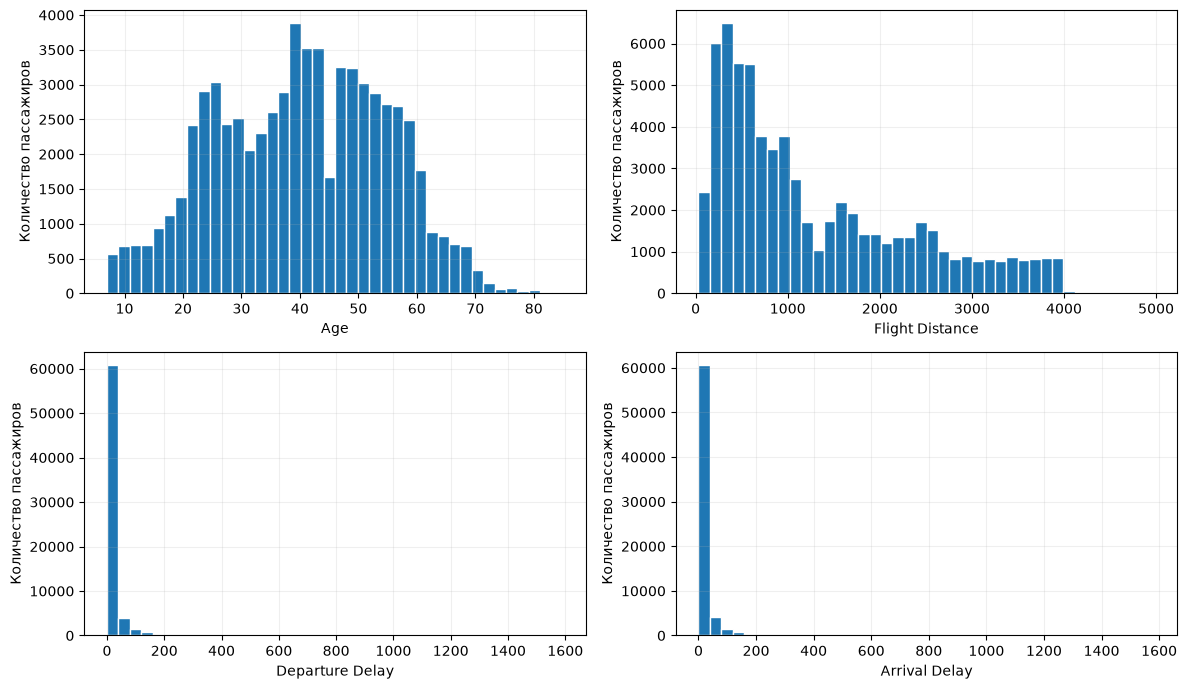

In [38]:
numerical_variables = ['Age', 'Flight Distance', 'Departure Delay', 'Arrival Delay']
outlier_rows = []

for column in numerical_variables:
    q1 = x_train[column].quantile(0.25)
    q3 = x_train[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    count = ((x_train[column] < lower_bound) | (x_train[column] > upper_bound)).sum()
    outlier_rows.append([column, lower_bound, upper_bound, count])

outliers = pd.DataFrame(outlier_rows, columns=[
    'Признак', 'Нижняя граница', 'Верхняя граница', 'Количество'
])
display(outliers.round(2))

plt.figure(figsize=(12, 7))
for i, column in enumerate(numerical_variables):
    plt.subplot(2, 2, i + 1)
    plt.hist(x_train[column], bins=40, edgecolor='white')
    plt.xlabel(column)
    plt.ylabel('Количество пассажиров')
    plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Обучение моделей

In [39]:
models = {
    'Дерево решений': DecisionTreeClassifier(
        max_depth=14, min_samples_leaf=8, random_state=42
    ),
    'Случайный лес': RandomForestClassifier(
        n_estimators=350, min_samples_leaf=1, n_jobs=4, random_state=42
    ),
    'Градиентный бустинг': HistGradientBoostingClassifier(
        max_iter=450, learning_rate=0.08, max_leaf_nodes=63,
        l2_regularization=3, early_stopping=False, random_state=42
    )
}

results = []

for name, model in models.items():
    start_time = time.perf_counter()
    model.fit(x_train, y_train)
    elapsed = time.perf_counter() - start_time

    y_valid_pred = model.predict(x_valid)

    results.append([
        name,
        accuracy_score(y_valid, y_valid_pred),
        precision_score(y_valid, y_valid_pred, zero_division=0),
        recall_score(y_valid, y_valid_pred, zero_division=0),
        f1_score(y_valid, y_valid_pred, zero_division=0),
        elapsed
    ])
    print(f'{name}: Accuracy = {accuracy_score(y_valid, y_valid_pred):.4f}, время = {elapsed:.2f} с')

Дерево решений: Accuracy = 0.9448, время = 0.36 с
Случайный лес: Accuracy = 0.9551, время = 9.14 с
Градиентный бустинг: Accuracy = 0.9581, время = 24.07 с


In [40]:
scores = pd.DataFrame(results, columns=[
    'Модель', 'Accuracy проверка',
    'Precision проверка', 'Recall проверка', 'F1 проверка', 'Время, с'
])
scores = scores.sort_values(
    ['Accuracy проверка', 'F1 проверка'], ascending=False
).reset_index(drop=True)
display(scores.round(4))

,Модель,Accuracy проверка,Precision проверка,Recall проверка,F1 проверка,"Время, с"
0,Градиентный бустинг,0.9581,0.9679,0.9634,0.9656,24.0691
1,Случайный лес,0.9551,0.9647,0.9617,0.9632,9.1448
2,Дерево решений,0.9448,0.9645,0.9445,0.9544,0.3638


## 7. Независимая итоговая оценка

In [41]:
best_name = scores.loc[0, 'Модель']
model = models[best_name]

y_valid_pred = model.predict(x_valid)

print(f'Лучшая модель: {best_name}')

Лучшая модель: Градиентный бустинг


## 8. Прогноз для test

Обучаем новую модель выбранного типа на всём train. Преобразования те же, что при проверке; медианы теперь вычисляются по всему train. Сохраняем порядок ID из шаблона.

In [ ]:
x_test = test_clean[features].copy()
medians = x_test.median()
x_test = x_test.fillna(medians)
model.fit(train_clean[features], y)

predictions = pd.read_csv('sample_submit.csv')
predictions = predictions.rename(columns={'index': 'ID'})
predictions['Satisfaction'] = model.predict(x_test).astype(int)

predictions.to_csv('predictions.csv', index=False)
display(predictions.head())

## Вывод

Модель выбрана по Accuracy на проверочной части, итоговые метрики получены на отдельной отложенной части. Затем выбранная модель переобучена на всём train и создан файл `predictions.csv`.

Метрики этого ноутбука относятся к данному запуску и подготовке данных. Из-за различия train и test они не являются оценкой точности на неизвестных ответах test.